## Catalogues
This notebook looks at the table **planed CMIP6 EURO-CORDEX EUR-12**
and compares it with the **catalogue about the available data at the Jülich server**

In [5]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
import intake
import pandas as pd
import os

import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

In [7]:
# create directory for plots
os.makedirs("plots", exist_ok=True)
plot_dir = "plots"
os.makedirs(plot_dir, exist_ok=True)

In [ ]:
df = pd.read_csv("CMIP6_downscaling_plans_checked_esgf.csv")
plot_cmip6_heatmaps(df, plot_dir, "server_esgf") 

In [75]:
def plot_cmip6_heatmaps(df, plot_dir, ext_plot_name):
    
    # Plotting the heatmaps for the CMIP6 downscaling plans, 
    # Catalogue in Jülich and optionally available at esgf
   
    # Kombination für x-Achse erzeugen
    df["gcm_variant"] = (
        df["driving_source_id"]
        + "\n"
        + df["driving_variant_label"]
    )

    # yes/no in 1/0 umwandeln
    df["value"] = df["in_catalog"].map({
        "yes": 2,
        "no": 1
    })
    esgf_yes = df["available at esgf"].eq("yes")
    df.loc[esgf_yes & df["in_catalog"].eq("no"), "value"] = 3
    df.loc[esgf_yes & df["in_catalog"].eq("yes"), "value"] = 4

    # Farben:
    from matplotlib.colors import ListedColormap

    cmap = ListedColormap([
        "lightgrey",  # 0 = not planned
      "#08306B",    # 1 = planned, unavailable in both
      "#CB181D",    # 2 = available in catalog only
      "#F4A261",    # 3 = available at ESGF only
      "#2A9D8F",    # 4 = available in both
    ])

    for experiment in sorted(df["driving_experiment_id"].unique()):

        sub = df[df["driving_experiment_id"] == experiment]

        heatmap_df = sub.pivot_table(
            index="gcm_variant",
            columns="source_id",
            values="value",
            aggfunc="max",
            fill_value=0
        )

        plt.figure(
            figsize=(
                max(12, len(heatmap_df.columns) * 0.4),
                max(6, len(heatmap_df.index) * 0.6)
            )
        )

        sns.heatmap(
            heatmap_df,
            cmap=cmap,
            cbar=False,
            linewidths=0.5,
            linecolor="white",
            vmin=0,
            vmax=4
        )
        if experiment in ["historical", "ssp370"]:  # example of multiple experiments to highlight
            ax = plt.gca()
            for label in ax.get_yticklabels():
                if label.get_text() in selected_variants:
                    label.set_color("red")
        if experiment in ["historical"]:
            title = f"{experiment} (also available: CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1, but EUR-12f)"
        else:
            title = f"{experiment}"
        plt.title(title)
        plt.ylabel("Driving GCM + Variant (red: selected GCMs balanced matrix)")
        plt.xlabel("Source ID")

        from matplotlib.patches import Patch

        legend_elements = [
            Patch(facecolor="lightgrey", label="not planned"),
            Patch(facecolor="#08306B", label="planned, unavailable in both"),
            Patch(facecolor="#CB181D", label="available in catalog only"),
            Patch(facecolor="#F4A261", label="available at ESGF only"),
            Patch(facecolor="#2A9D8F", label="available in both"),
        ]

        plt.legend(
            handles=legend_elements,
            bbox_to_anchor=(1.02, 1),
            loc="upper left"
        )

        plt.tight_layout()

        plt.savefig(
            f"{plot_dir}/heatmap_{experiment}_{ext_plot_name}.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()

In [8]:
# URL to the CMIP6 downscaling plans CSV file (Jesus Table)
# also have a look here:
# https://wcrp-cordex.github.io/simulation-status/CORDEX_CMIP6_status.html#EUR-12

url = "https://raw.githubusercontent.com/WCRP-CORDEX/simulation-status/main/CMIP6_downscaling_plans.csv"
df = pd.read_csv(url)
df.head()
#
df.columns

Index(['domain_id', 'institution_id', 'contact', 'source_id',
       'driving_source_id', 'driving_variant_label', 'driving_experiment_id',
       'status', 'estimated_completion_date', 'comments'],
      dtype='str')

In [10]:
df_eurbalanced = df.loc[
    df["comments"].str.contains("#EURbalanced", na=False, regex=False)
].copy()

df_eurbalanced['driving_source_id'].unique()

<ArrowStringArray>
['MPI-ESM1-2-HR',    'NorESM2-MM',          'ERA5',        'MIROC6',
  'CMCC-CM2-SR5', 'EC-Earth3-Veg',   'CNRM-ESM2-1']
Length: 7, dtype: str

### Select what I need from planed simulations e.g. EUR-12

In [14]:
# ------------------------------------------------------------------
# Domsi selection for EUR-12 domain
# ------------------------------------------------------------------
df_eur12=df[df['domain_id']=='EUR-12']
# ------------------------------------------------------------------
# There are some rows containing EURO-CORDEX as institution_id, 
# we don not need
# ------------------------------------------------------------------
df_eur12=df_eur12[df_eur12['institution_id']!='EURO-CORDEX']
df_eur12.head()
# ------------------------------------------------------------------
# select colums of interest
# ------------------------------------------------------------------
df_eur12_small = df_eur12[['institution_id', 'source_id', 'driving_source_id', 'driving_variant_label', 'driving_experiment_id','comments']]
# ------------------------------------------------------------------
# we only want historical and ssps:
# ------------------------------------------------------------------
df_eur12_small=df_eur12_small[df_eur12_small['driving_source_id']!='ERA5']
df_eur12_small.to_csv("df_eur12_small.csv", index=False)
df_eur12_small.head()

,institution_id,source_id,driving_source_id,driving_variant_label,driving_experiment_id,comments
336,AUTH,WRF451Q,MPI-ESM1-2-HR,r1i1p1f1,historical,#EURbalanced #ManySSP #CORDEX-CORE
337,AUTH,WRF451Q,MPI-ESM1-2-HR,r1i1p1f1,ssp126,#EURbalanced #ManySSP
338,BCCR-UCAN,WRF451Q,NorESM2-MM,r1i1p1f1,historical,#EURbalanced #CORDEX-CORE
339,BCCR-UCAN,WRF451Q,NorESM2-MM,r1i1p1f1,ssp126,#EURbalanced
340,BCCR-UCAN,WRF451Q,NorESM2-MM,r1i1p1f1,ssp370,#EURbalanced #CORDEX-CORE


### Available in Jülich

In [15]:
cat = intake.open_esm_datastore("https://raw.githubusercontent.com/euro-cordex/jsc-cordex-catalog/refs/heads/main/CORDEX-CMIP6-JSC.json")
#cat#.keys()

### Available, but wrong format

In [16]:
# perhaps also available in Jülich, but only wrong format:
# failed parsing entries
url_not="https://raw.githubusercontent.com/euro-cordex/jsc-cordex-catalog/main/failed_parsing.csv"
print(url_not)
failed_df = pd.read_csv(url_not)
list=failed_df["path"].apply(os.path.basename)
day_files = list[list.str.contains("day", case=False, na=False)]
day_files = day_files.str.replace(
    r"(?i)(day).*",
    r"\1",
    regex=True
)

day_files.unique()


https://raw.githubusercontent.com/euro-cordex/jsc-cordex-catalog/main/failed_parsing.csv


<ArrowStringArray>
[       'vas_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
       'huss_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
        'tas_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
    'sfcWind_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
       'rsds_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
        'uas_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
        'clt_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
 'sfcWindmax_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
     'tasmin_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
    'evspsbl_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
     'tasmax_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1-r1_day',
       'rlds_EUR-12f_CMCC-CM2-SR5_historical_r1i1p1f1_TAS

### Comparison of what is planned and what is available in the catalog in Jülich

In [17]:
# This is the comparison of what is planned and what is available in the catalog
#
# ------------------------------------------------------------------
# CSV containing planned downscaling
# ------------------------------------------------------------------

df = pd.read_csv("df_eur12_small.csv")

# ------------------------------------------------------------------
# Intake-ESM Catalog with available simulations in Jülich
# ------------------------------------------------------------------

cat = intake.open_esm_datastore("https://raw.githubusercontent.com/euro-cordex/jsc-cordex-catalog/refs/heads/main/CORDEX-CMIP6-JSC.json")
cdf = cat.df

# ------------------------------------------------------------------
# Columns that together describe a model chain
# ------------------------------------------------------------------

match_cols = [
    "institution_id",
    "source_id",
    "driving_source_id",
    "driving_variant_label",
    "driving_experiment_id",
]

# ------------------------------------------------------------------
# Required variables
# ------------------------------------------------------------------

required_vars = {"tas", "pr"}
#required_vars = {"tas", "pr", "tasmin", "tasmax"}

# ------------------------------------------------------------------
# Only consider daily data
# ------------------------------------------------------------------

cdf_day = cdf[cdf["frequency"] == "day"]

# ------------------------------------------------------------------
# Which variables are available for each model chain?
# ------------------------------------------------------------------

available = (
    cdf_day.groupby(match_cols)["variable_id"]
    .agg(lambda x: set(x))
    .reset_index()
)

# ------------------------------------------------------------------
# Are all required variables available?
# ------------------------------------------------------------------

available["in_catalog"] = available["variable_id"].apply(
    lambda x: required_vars.issubset(set(x))
)

# ------------------------------------------------------------------
# Which variables are missing?
# ------------------------------------------------------------------

available["missing_variables"] = available["variable_id"].apply(
    lambda x: ",".join(sorted(required_vars - set(x))))


# ------------------------------------------------------------------
# Merge with the original CSV
# ------------------------------------------------------------------

df = df.merge(
    available,
    on=match_cols,
    how="left"
)

# ------------------------------------------------------------------
# Combination not found in the catalog
# ------------------------------------------------------------------

df["in_catalog"] = df["in_catalog"].fillna(False)

df["missing_variables"] = df["missing_variables"].fillna(
    "combination_not_found"
)

# ------------------------------------------------------------------
# Convert True/False to yes/no
# ------------------------------------------------------------------

df["in_catalog"] = df["in_catalog"].map(
    {True: "yes", False: "no"}
)

# ------------------------------------------------------------------
# Save
# ------------------------------------------------------------------

df.to_csv(
    "CMIP6_downscaling_plans_checked.csv",
    index=False
)

print(df["in_catalog"].value_counts())

in_catalog
no     106
yes     72
Name: count, dtype: int64


# select balanced matrix

In [18]:
df = pd.read_csv("CMIP6_downscaling_plans_checked.csv")

# only balance matrix
df_eurbalanced = df.loc[
    df["comments"].str.contains("#EURbalanced", na=False, regex=False)
].copy()

df_eurbalanced['driving_source_id'].unique()


<ArrowStringArray>
['MPI-ESM1-2-HR',    'NorESM2-MM',        'MIROC6',  'CMCC-CM2-SR5',
 'EC-Earth3-Veg',   'CNRM-ESM2-1']
Length: 6, dtype: str

# Create plots

In [19]:
# Just for fancy plots, I like to high light the simulations of the balanced matrix
# or you aloso have only the simulations from the balance matrix

df_eurbalanced["gcm_variant"] = (
    df_eurbalanced["driving_source_id"]
    + "\n"
    + df_eurbalanced["driving_variant_label"]
)
selected_variants = df_eurbalanced["gcm_variant"].unique()
selected_variants


<ArrowStringArray>
['MPI-ESM1-2-HR\nr1i1p1f1',    'NorESM2-MM\nr1i1p1f1',
        'MIROC6\nr1i1p1f1',  'CMCC-CM2-SR5\nr1i1p1f1',
 'EC-Earth3-Veg\nr1i1p1f1',   'CNRM-ESM2-1\nr1i1p1f2']
Length: 6, dtype: str

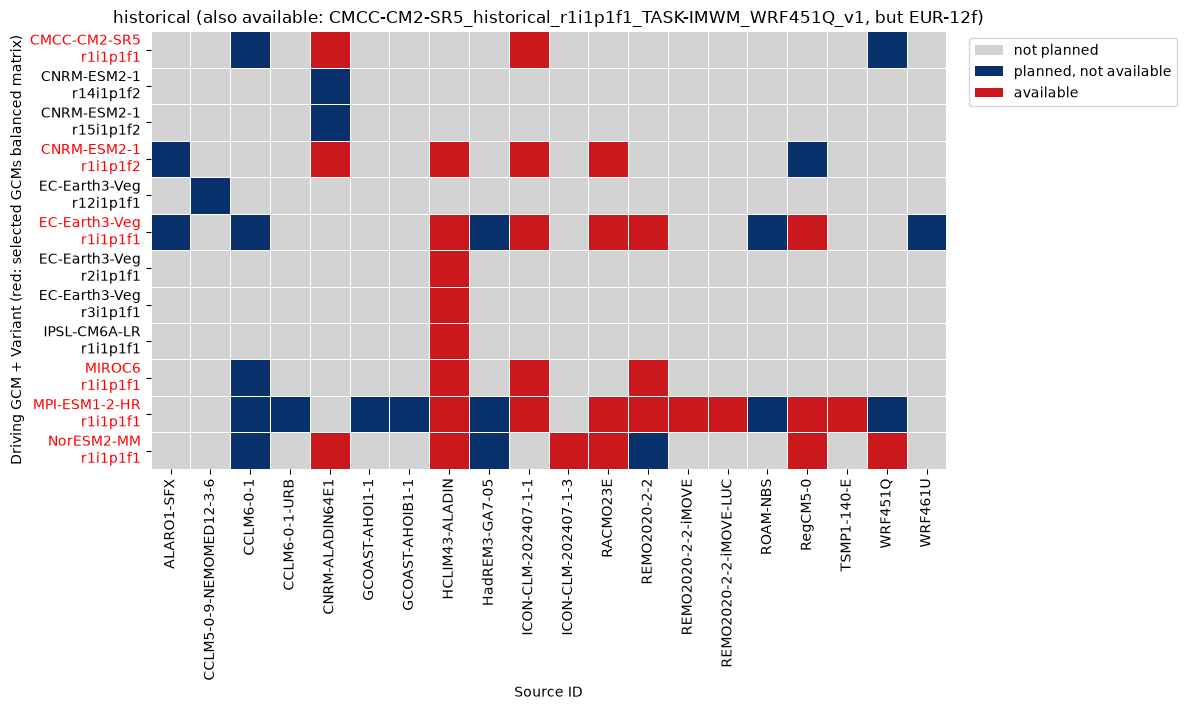

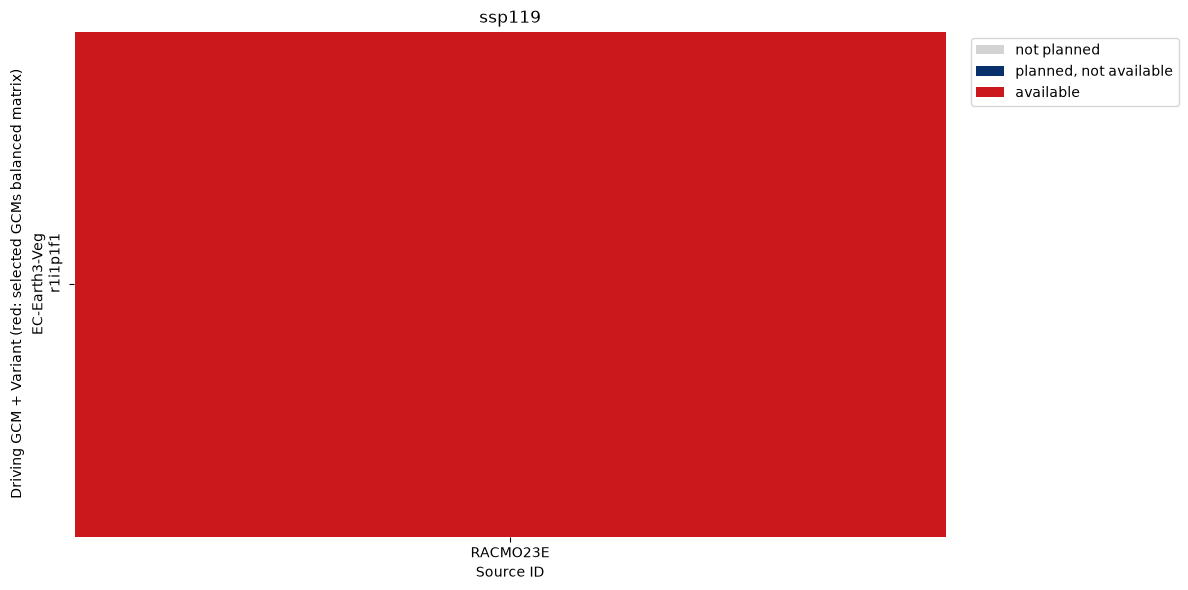

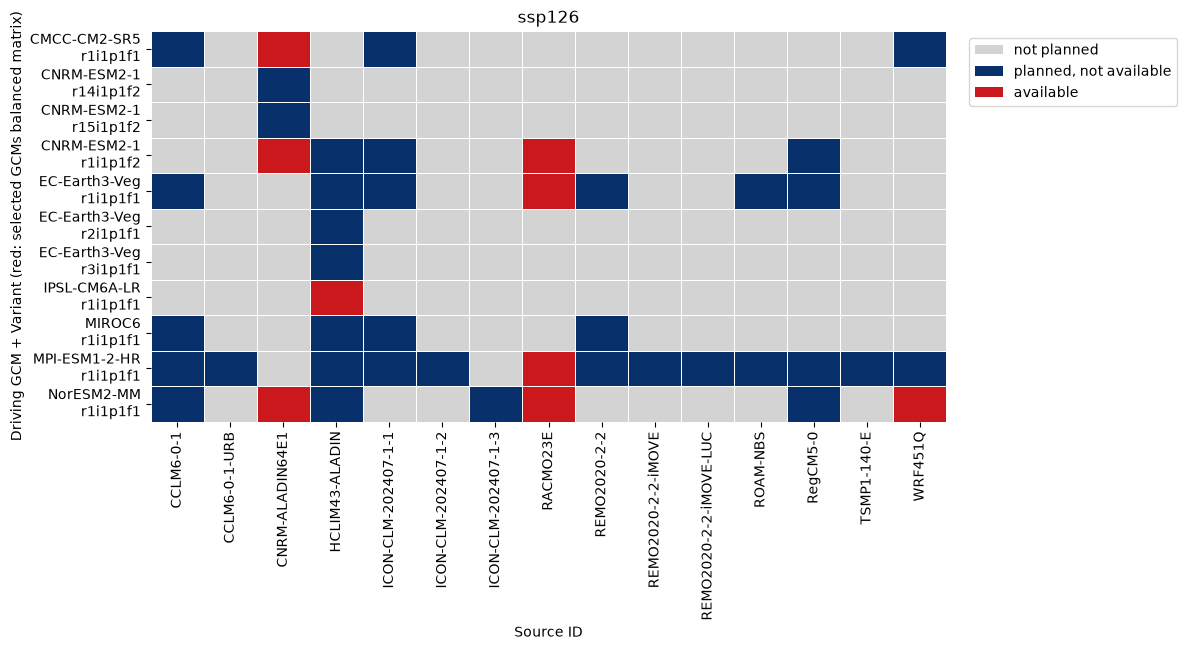

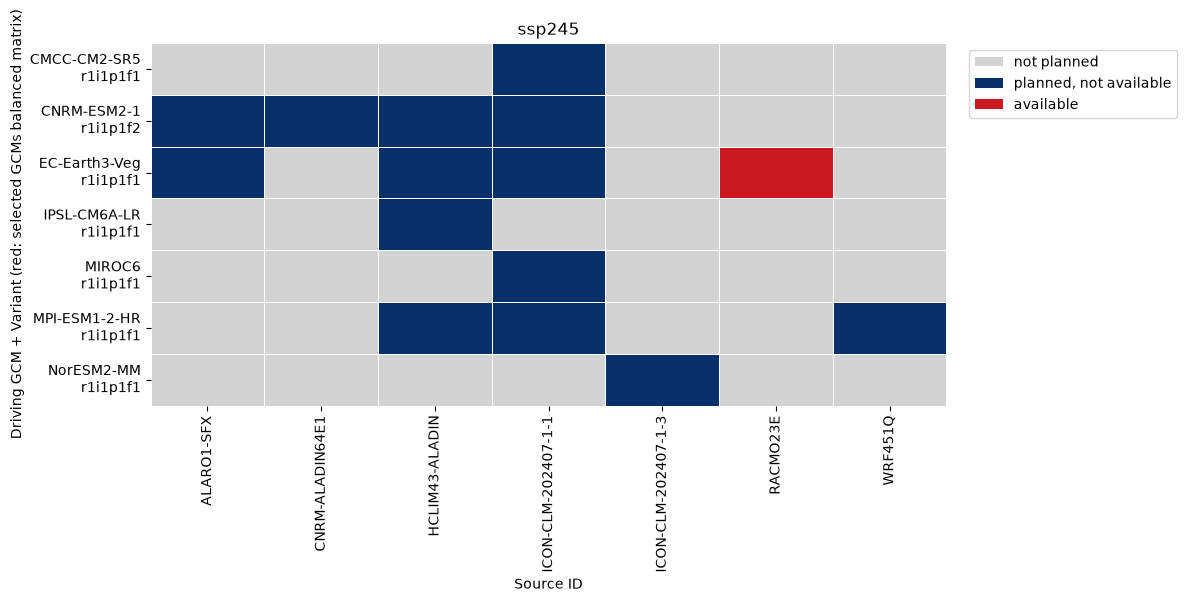

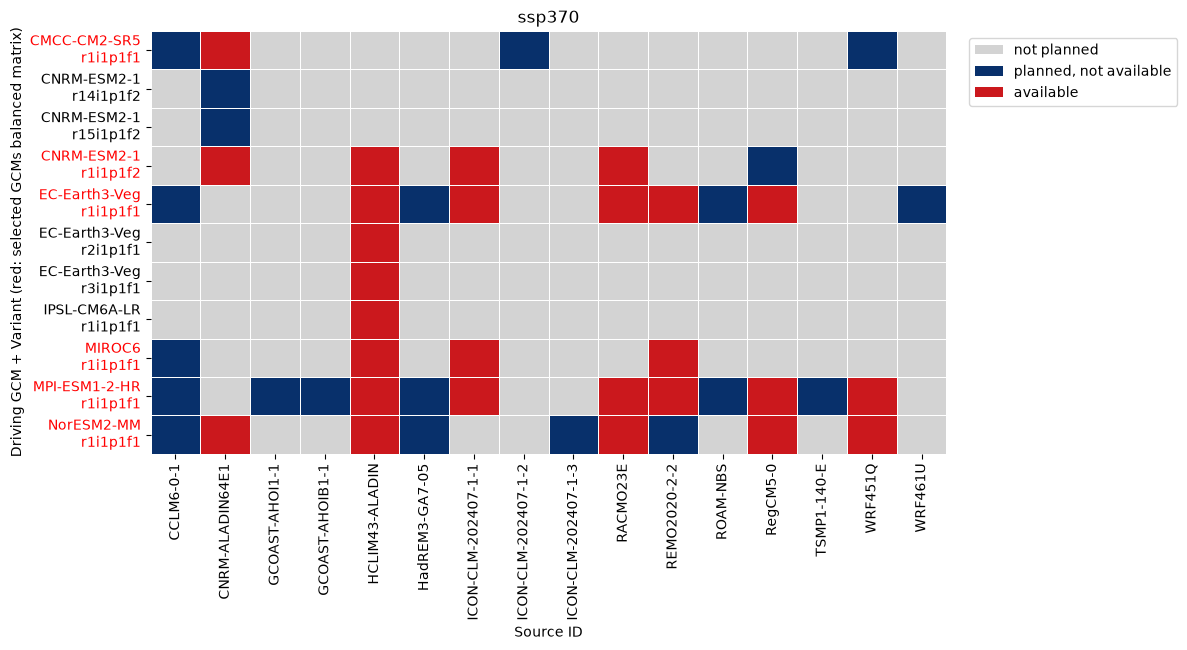

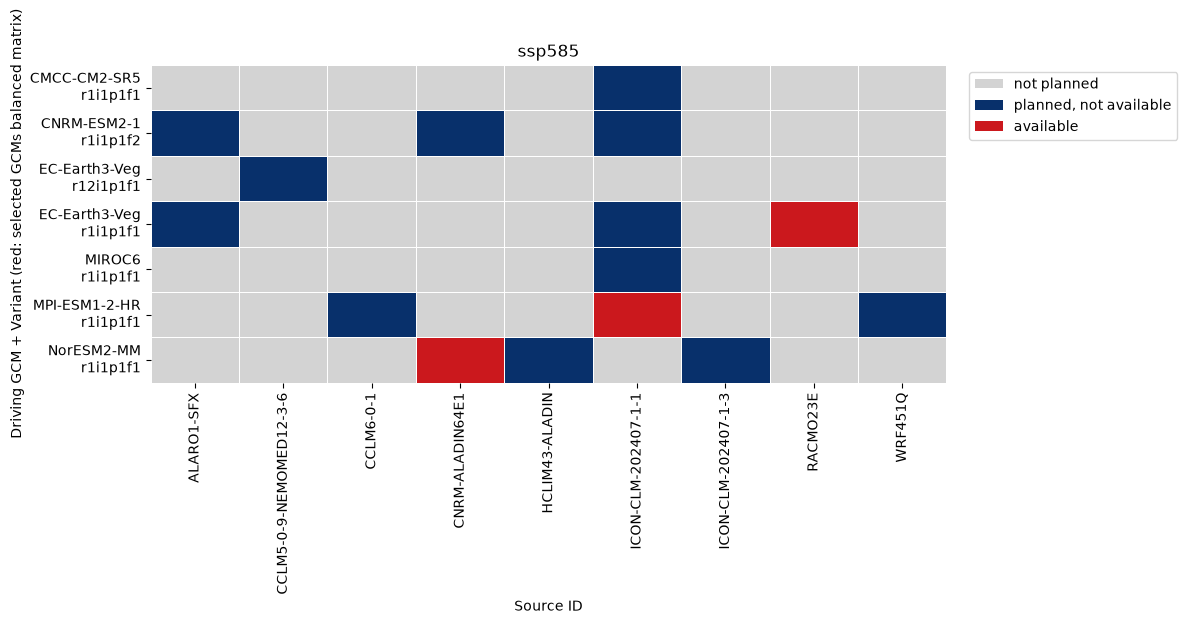

In [20]:
# ------------------------------------------------------------------
# Plotting the heatmaps for the CMIP6 downscaling plans
# ------------------------------------------------------------------
df = pd.read_csv("CMIP6_downscaling_plans_checked.csv")

# Kombination für x-Achse erzeugen
df["gcm_variant"] = (
    df["driving_source_id"]
    + "\n"
    + df["driving_variant_label"]
)

# change yes/no in 1/0
df["value"] = df["in_catalog"].map({
    "yes": 2,
    "no": 1
})

# colors:
from matplotlib.colors import ListedColormap

cmap = ListedColormap([
    "lightgrey",  # 0 = not in CSV
    "#08306B",    # 1 = no (blue)
    "#CB181D",    # 2 = yes (red)
])

for experiment in sorted(df["driving_experiment_id"].unique()):

    sub = df[df["driving_experiment_id"] == experiment]

    heatmap_df = sub.pivot_table(
        index="gcm_variant",
        columns="source_id",
        values="value",
        aggfunc="max",
        fill_value=0
    )

    plt.figure(
        figsize=(
            max(12, len(heatmap_df.columns) * 0.4),
            max(6, len(heatmap_df.index) * 0.6)
        )
    )

    sns.heatmap(
        heatmap_df,
        cmap=cmap,
        cbar=False,
        linewidths=0.5,
        linecolor="white",
        vmin=0,
        vmax=2
    )
    if experiment in ["historical", "ssp370"]:  # example of multiple experiments to highlight
        ax = plt.gca()
        for label in ax.get_yticklabels():
            if label.get_text() in selected_variants:
                label.set_color("red")
    # ------------------------------------------------------------------
    # The following can change, have a look at the output above
    # ------------------------------------------------------------------
    # The comment is added by hand, needs to be checked
    # ------------------------------------------------------------------
    
    if experiment in ["historical"]:
        title = f"{experiment} (also available: CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1, but EUR-12f)"
    else:
        title = f"{experiment}"
    plt.title(title)
    plt.ylabel("Driving GCM + Variant (red: selected GCMs balanced matrix)")
    plt.xlabel("Source ID")

    from matplotlib.patches import Patch

    legend_elements = [
        Patch(facecolor="lightgrey", label="not planned"),
        Patch(facecolor="#08306B", label="planned, not available"),
        Patch(facecolor="#CB181D", label="available"),
    ]

    plt.legend(
        handles=legend_elements,
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
  

    plt.savefig(
        f"{plot_dir}/heatmap_{experiment}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

# Balanced Matrix

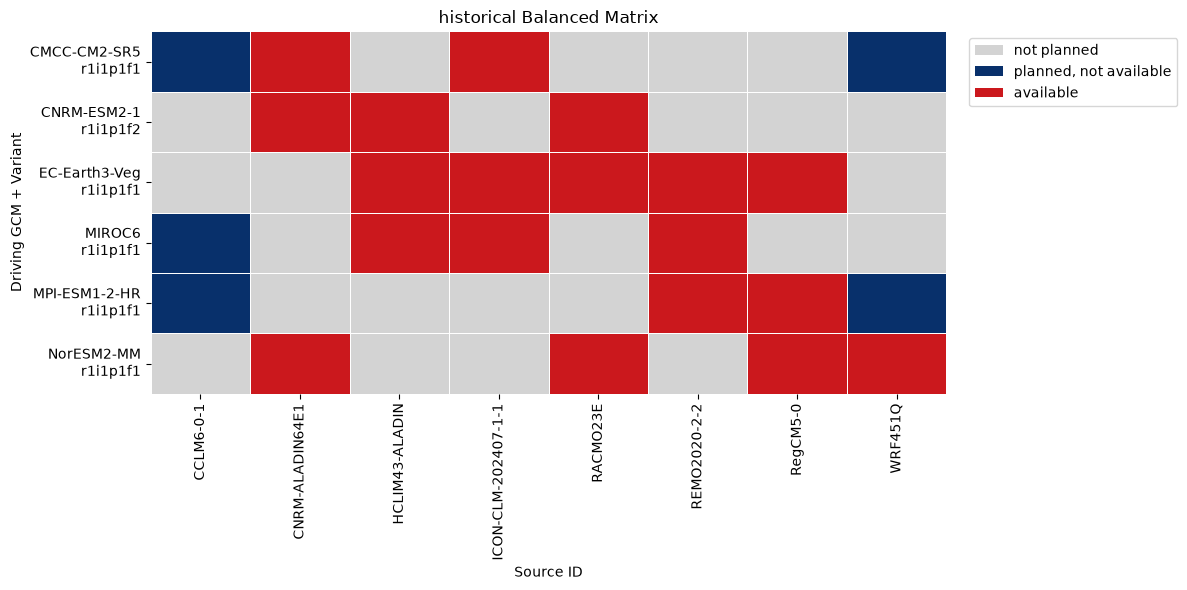

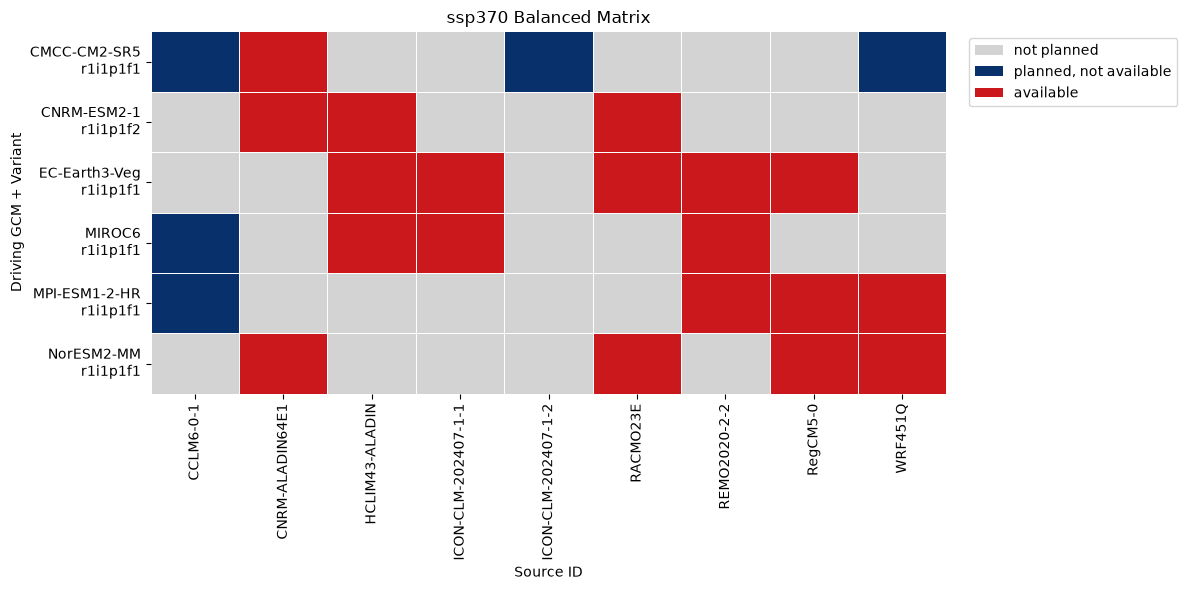

In [21]:
# ------------------------------------------------------------------
# Plot just balanced matrix:
# ------------------------------------------------------------------
# load df
# ------------------------------------------------------------------

df_bm = df_eurbalanced

# Kombination for x-Achse erzeugen
df_bm["gcm_variant"] = (
    df_bm["driving_source_id"]
    + "\n"
    + df_bm["driving_variant_label"]
)

# change yes/no in 1/0
df_bm["value"] = df_bm["in_catalog"].map({
    "yes": 2,
    "no": 1
})

# colors:
from matplotlib.colors import ListedColormap

cmap = ListedColormap([
    "lightgrey",  # 0 = not in CSV
    "#08306B",    # 1 = no (blue)
    "#CB181D",    # 2 = yes (red)
])

for experiment in ['historical', 'ssp370'] : #sorted(df_bm["driving_experiment_id"].unique()):

    sub = df_bm[df_bm["driving_experiment_id"] == experiment]

    heatmap_df = sub.pivot_table(
        index="gcm_variant",
        columns="source_id",
        values="value",
        aggfunc="max",
        fill_value=0
    )

    plt.figure(
        figsize=(
            max(12, len(heatmap_df.columns) * 0.4),
            max(6, len(heatmap_df.index) * 0.6)
        )
    )

    sns.heatmap(
        heatmap_df,
        cmap=cmap,
        cbar=False,
        linewidths=0.5,
        linecolor="white",
        vmin=0,
        vmax=2
    )
    
    title = f"{experiment} Balanced Matrix"
    plt.title(title)
    plt.ylabel("Driving GCM + Variant")
    plt.xlabel("Source ID")

    from matplotlib.patches import Patch

    legend_elements = [
        Patch(facecolor="lightgrey", label="not planned"),
        Patch(facecolor="#08306B", label="planned, not available"),
        Patch(facecolor="#CB181D", label="available"),
    ]

    plt.legend(
        handles=legend_elements,
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()

    plt.savefig(
        f"{plot_dir}/heatmap_{experiment}_balance_matrix.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()



# Test reading esgf search results

In [51]:
import json

with open("search.geojson", "r") as search_file:
    search_data = search_file.read()

search_df = pd.json_normalize(
    json.loads(search_data)["features"],
    sep="."
)
search_df['id'].unique()

<ArrowStringArray>
[              'CORDEX-CMIP6.DD.EUR-12.CNRM-MF.NorESM2-MM.ssp585.r1i1p1f1.CNRM-ALADIN64E1.v1-r1.day.tasmin.v20260811',
               'CORDEX-CMIP6.DD.EUR-12.CNRM-MF.NorESM2-MM.ssp585.r1i1p1f1.CNRM-ALADIN64E1.v1-r1.day.tasmax.v20260811',
                  'CORDEX-CMIP6.DD.EUR-12.CNRM-MF.NorESM2-MM.ssp585.r1i1p1f1.CNRM-ALADIN64E1.v1-r1.day.tas.v20260811',
                   'CORDEX-CMIP6.DD.EUR-12.CNRM-MF.NorESM2-MM.ssp585.r1i1p1f1.CNRM-ALADIN64E1.v1-r1.day.pr.v20260811',
               'CORDEX-CMIP6.DD.EUR-12.CNRM-MF.NorESM2-MM.ssp370.r1i1p1f1.CNRM-ALADIN64E1.v1-r1.day.tasmin.v20260810',
               'CORDEX-CMIP6.DD.EUR-12.CNRM-MF.NorESM2-MM.ssp370.r1i1p1f1.CNRM-ALADIN64E1.v1-r1.day.tasmax.v20260810',
                  'CORDEX-CMIP6.DD.EUR-12.CNRM-MF.NorESM2-MM.ssp370.r1i1p1f1.CNRM-ALADIN64E1.v1-r1.day.tas.v20260810',
                   'CORDEX-CMIP6.DD.EUR-12.CNRM-MF.NorESM2-MM.ssp370.r1i1p1f1.CNRM-ALADIN64E1.v1-r1.day.pr.v20260810',
               'CORDEX-CMIP6.

# Open esgf search

https://metagrid-ceda.east.esgf.io/search
22 Okt 2026

In [58]:
import json

with open("search.geojson", "r") as search_file:
    search_data = search_file.read()

search_df = pd.json_normalize(
    json.loads(search_data)["features"],
    sep="."
)

id_parts = search_df["id"].str.split(".", expand=True)
base_id_columns = [
    "project",
    "activity_id",
    "domain_id",
    "institution_id",
    "driving_source_id",
    "driving_experiment_id",
    "driving_variant_label",
    "source_id",
    "version_realization",
    "frequency",
    "variable_id",
    "data_version",
]
id_parts.columns = [
    base_id_columns[index] if index < len(base_id_columns) else f"id_part_{index + 1}"
    for index in range(id_parts.shape[1])
]

search_df_split = pd.concat([search_df[["id"]], id_parts], axis=1)
search_df_split.to_csv("search_df_split_id.csv", index=False)
search_df_split



,id,project,activity_id,domain_id,institution_id,driving_source_id,driving_experiment_id,driving_variant_label,source_id,version_realization,frequency,variable_id,data_version
0,CORDEX-CMIP6.DD.EUR-12.CNRM-MF.NorESM2-MM.ssp5...,CORDEX-CMIP6,DD,EUR-12,CNRM-MF,NorESM2-MM,ssp585,r1i1p1f1,CNRM-ALADIN64E1,v1-r1,day,tasmin,v20260811
1,CORDEX-CMIP6.DD.EUR-12.CNRM-MF.NorESM2-MM.ssp5...,CORDEX-CMIP6,DD,EUR-12,CNRM-MF,NorESM2-MM,ssp585,r1i1p1f1,CNRM-ALADIN64E1,v1-r1,day,tasmax,v20260811
2,CORDEX-CMIP6.DD.EUR-12.CNRM-MF.NorESM2-MM.ssp5...,CORDEX-CMIP6,DD,EUR-12,CNRM-MF,NorESM2-MM,ssp585,r1i1p1f1,CNRM-ALADIN64E1,v1-r1,day,tas,v20260811
3,CORDEX-CMIP6.DD.EUR-12.CNRM-MF.NorESM2-MM.ssp5...,CORDEX-CMIP6,DD,EUR-12,CNRM-MF,NorESM2-MM,ssp585,r1i1p1f1,CNRM-ALADIN64E1,v1-r1,day,pr,v20260811
4,CORDEX-CMIP6.DD.EUR-12.CNRM-MF.NorESM2-MM.ssp3...,CORDEX-CMIP6,DD,EUR-12,CNRM-MF,NorESM2-MM,ssp370,r1i1p1f1,CNRM-ALADIN64E1,v1-r1,day,tasmin,v20260810
...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,CORDEX-CMIP6.DD.EUR-12.CLMcom-Hereon.ERA5.eval...,CORDEX-CMIP6,DD,EUR-12,CLMcom-Hereon,ERA5,evaluation,r1i1p1f1,ICON-CLM-202407-1-1,v1-r2,day,pr,v20260415
96,CORDEX-CMIP6.DD.EUR-12.CLMcom-Hereon.ERA5.eval...,CORDEX-CMIP6,DD,EUR-12,CLMcom-Hereon,ERA5,evaluation,r1i1p1f1,ICON-CLM-202407-1-1,v1-r1,day,tasmin,v20260415
97,CORDEX-CMIP6.DD.EUR-12.CLMcom-Hereon.ERA5.eval...,CORDEX-CMIP6,DD,EUR-12,CLMcom-Hereon,ERA5,evaluation,r1i1p1f1,ICON-CLM-202407-1-1,v1-r1,day,tasmax,v20260415
98,CORDEX-CMIP6.DD.EUR-12.CLMcom-Hereon.ERA5.eval...,CORDEX-CMIP6,DD,EUR-12,CLMcom-Hereon,ERA5,evaluation,r1i1p1f1,ICON-CLM-202407-1-1,v1-r1,day,tas,v20260415


# Combine CMIP6 down scaling plans checked at Jülich with available simulations in esgf

In [69]:
#-----------------------------------------------------
# Load CMIP6 downscaling plans check availability at Jülich
#-----------------------------------------------------

df = pd.read_csv("CMIP6_downscaling_plans_checked.csv")
#-----------------------------------------------------
# Load ESGF search results for daily data
#-----------------------------------------------------
 
search_df_split = pd.read_csv("search_df_split_id.csv")

# Only consider daily data from the ESGF search
esgf_day = search_df_split[search_df_split["frequency"] == "day"]


# Which variables are available for each model chain at ESGF?
#esgf_available = (
#    esgf_day.groupby(match_cols)["variable_id"]
#    .agg(lambda x: set(x))
#    .reset_index()
#    .rename(columns={"variable_id": "esgf_variables"})
#)

esgf_available = (
    esgf_day.groupby(match_cols)["variable_id"]
    .agg(
        lambda values: {
            variable.strip()
            for value in values.dropna()
            for variable in str(value).split(",")
            if variable.strip()
        }
    )
    .reset_index()
    .rename(columns={"variable_id": "esgf_variables"})
)

required_vars = {"tas", "pr"}

esgf_available["available at esgf"] = esgf_available["esgf_variables"].apply(
    lambda variables: required_vars.issubset(variables)
)

# Are all required variables available?
esgf_available["available at esgf"] = esgf_available["esgf_variables"].apply(
    lambda x: required_vars.issubset(x)
)

# Which variables are missing at ESGF?
esgf_available["missing_variables_esgf"] = esgf_available["esgf_variables"].apply(
    lambda x: ",".join(sorted(required_vars - x))
)

# Merge with the planned simulations
df = df.merge(
    esgf_available.drop(columns="esgf_variables"),
    on=match_cols,
    how="left"
)

# Combination not found at ESGF
df["available at esgf"] = df["available at esgf"].fillna(False)
df["missing_variables_esgf"] = df["missing_variables_esgf"].fillna(
    "combination_not_found"
)

# Convert True/False to yes/no
df["available at esgf"] = df["available at esgf"].map({True: "yes", False: "no"})

df.to_csv("CMIP6_downscaling_plans_checked_esgf.csv", index=False)


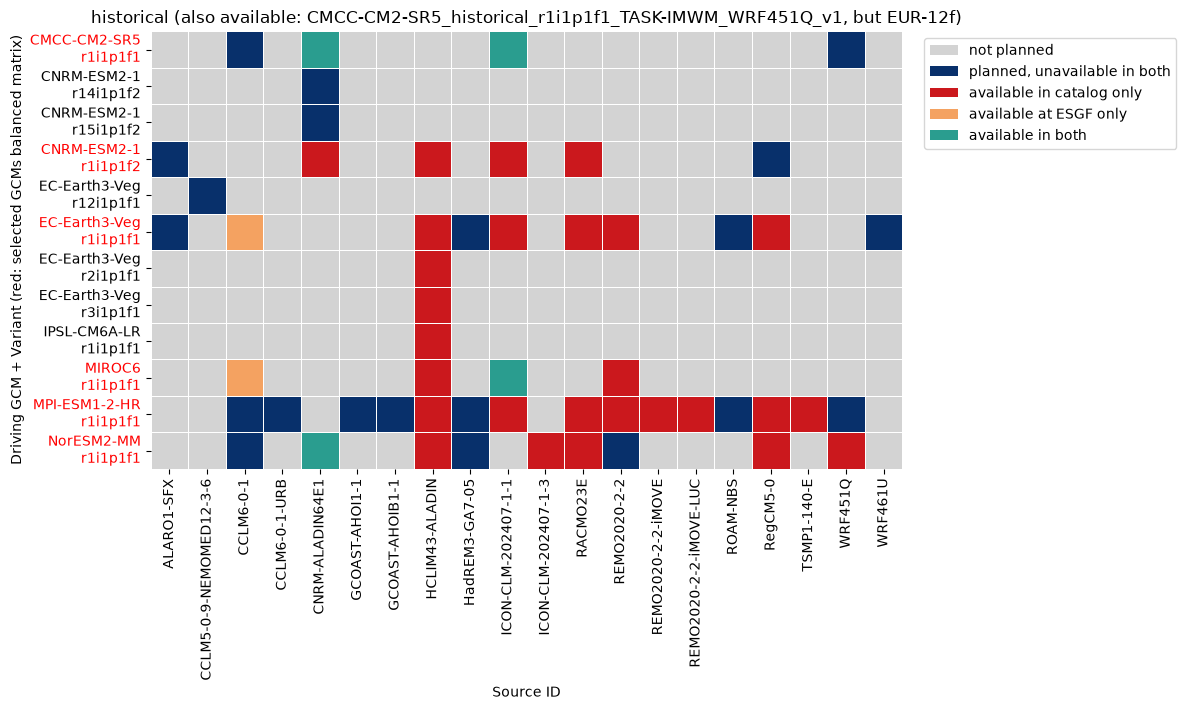

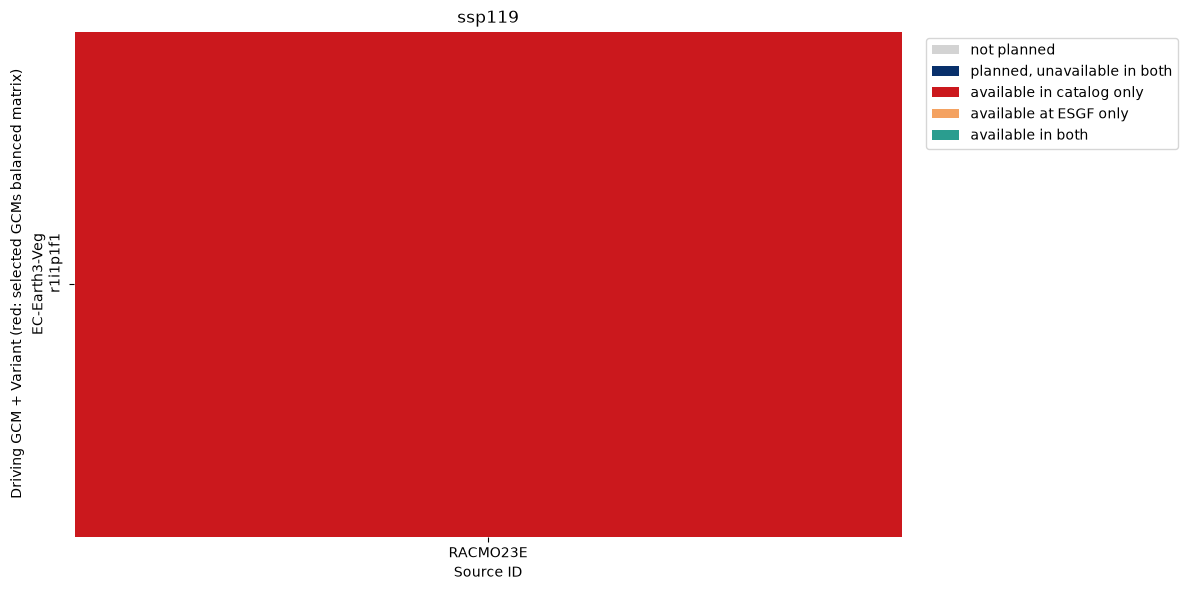

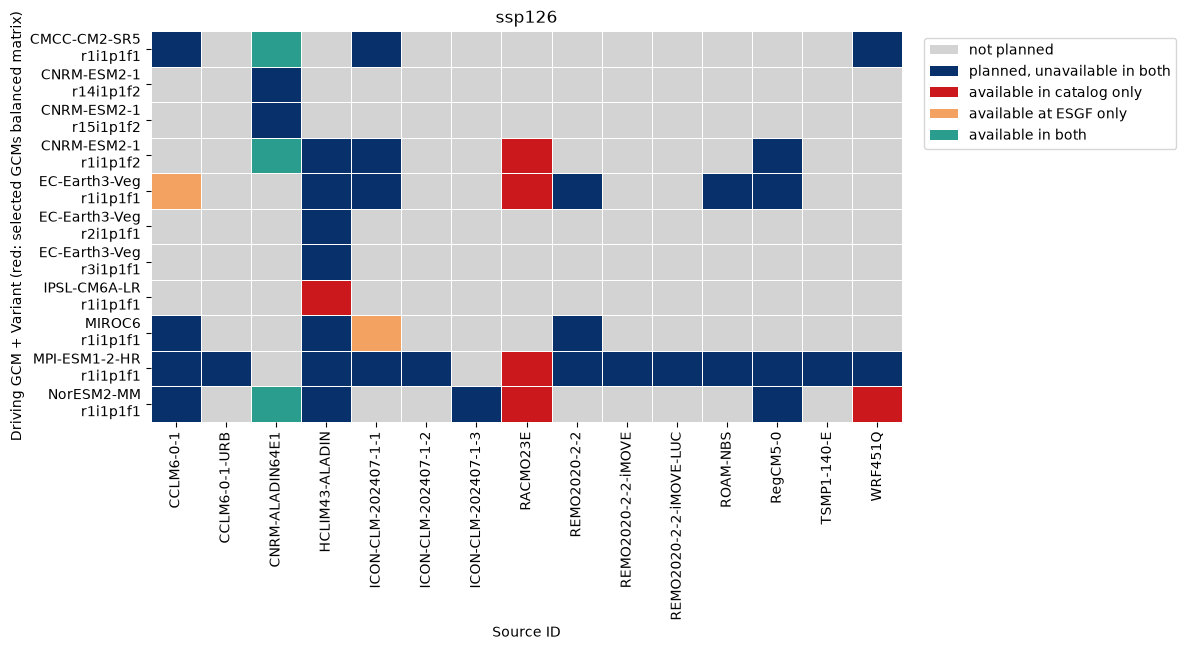

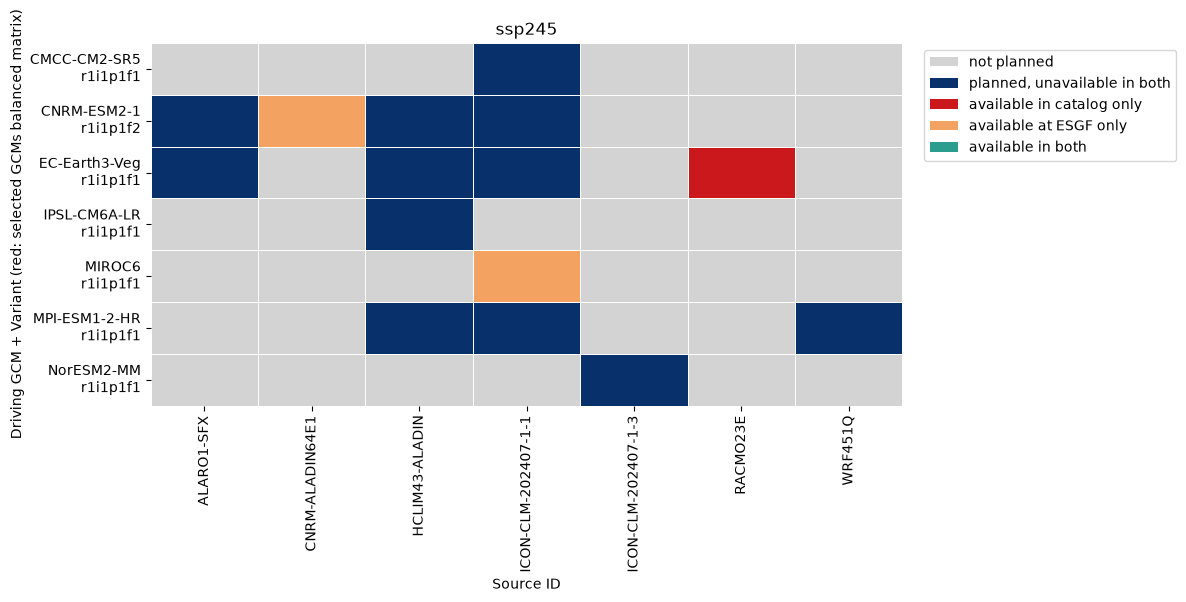

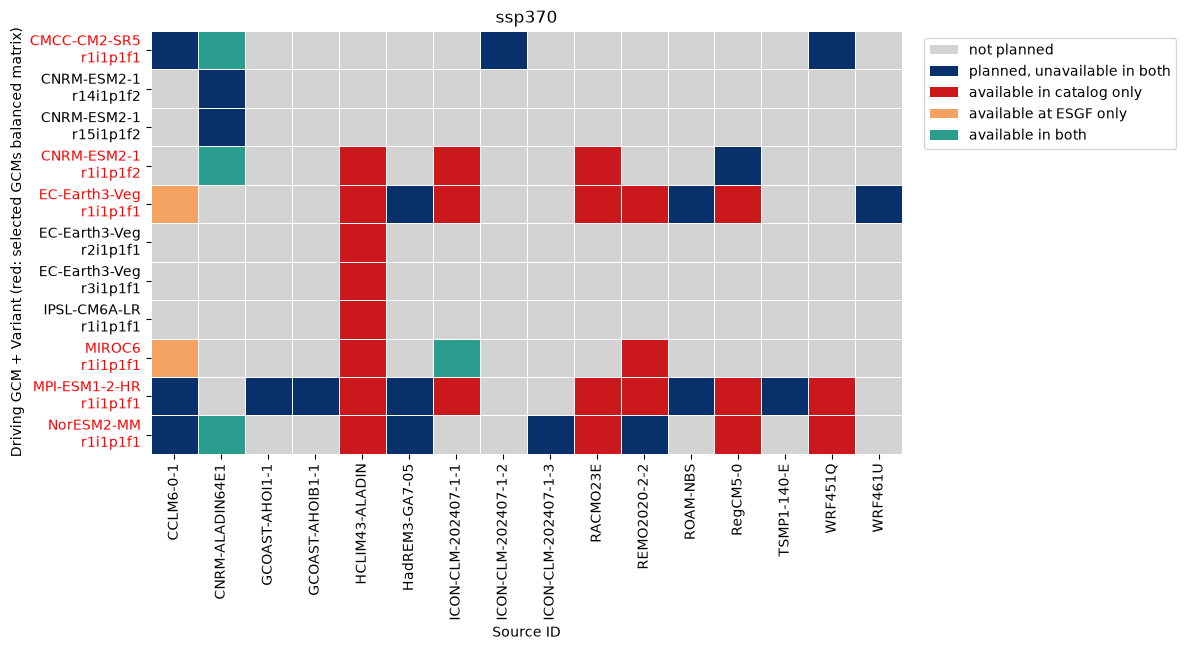

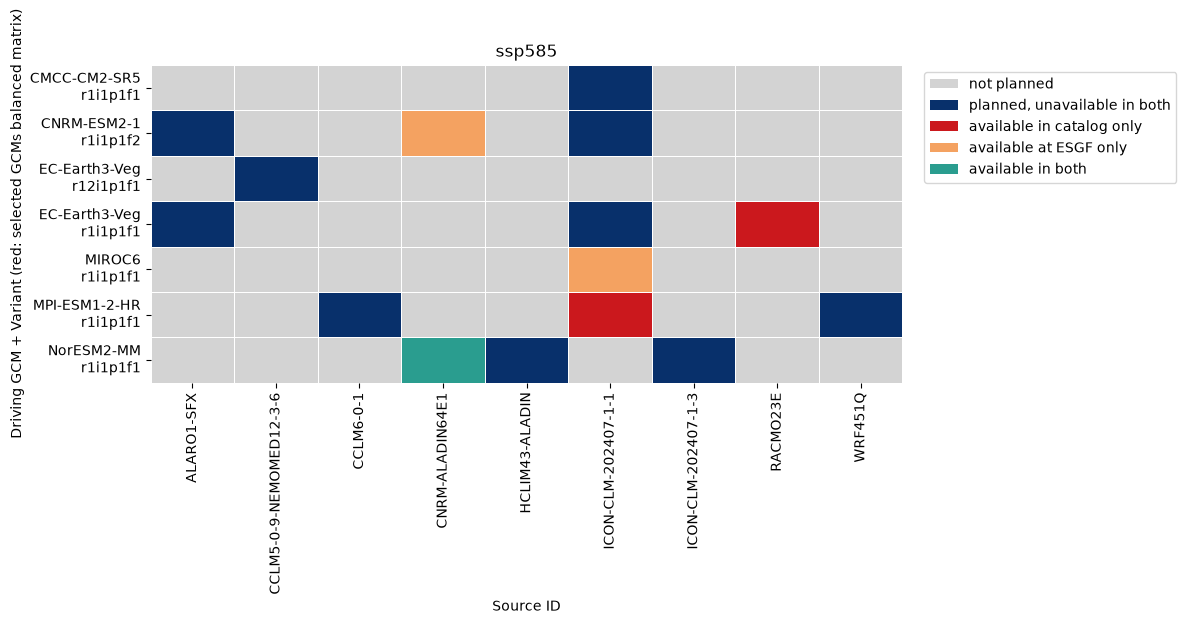

In [70]:
# Plotting the heatmaps for the CMIP6 downscaling plans, Catalogue in Jülich, available at esgf
#-----------------------------------------------------
# Load CMIP6 downscaling plans check availability at Jülich
#-----------------------------------------------------

df = pd.read_csv("CMIP6_downscaling_plans_checked_esgf.csv")


# Kombination für x-Achse erzeugen
df["gcm_variant"] = (
    df["driving_source_id"]
    + "\n"
    + df["driving_variant_label"]
)

# yes/no in 1/0 umwandeln
df["value"] = df["in_catalog"].map({
    "yes": 2,
    "no": 1
})
esgf_yes = df["available at esgf"].eq("yes")
df.loc[esgf_yes & df["in_catalog"].eq("no"), "value"] = 3
df.loc[esgf_yes & df["in_catalog"].eq("yes"), "value"] = 4

# Farben:
from matplotlib.colors import ListedColormap

cmap = ListedColormap([
    "lightgrey",  # 0 = not planned
    "#08306B",    # 1 = planned, unavailable in both
    "#CB181D",    # 2 = available in catalog only
    "#F4A261",    # 3 = available at ESGF only
    "#2A9D8F",    # 4 = available in both
])

for experiment in sorted(df["driving_experiment_id"].unique()):

    sub = df[df["driving_experiment_id"] == experiment]

    heatmap_df = sub.pivot_table(
        index="gcm_variant",
        columns="source_id",
        values="value",
        aggfunc="max",
        fill_value=0
    )

    plt.figure(
        figsize=(
            max(12, len(heatmap_df.columns) * 0.4),
            max(6, len(heatmap_df.index) * 0.6)
        )
    )

    sns.heatmap(
        heatmap_df,
        cmap=cmap,
        cbar=False,
        linewidths=0.5,
        linecolor="white",
        vmin=0,
        vmax=4
    )
    if experiment in ["historical", "ssp370"]:  # example of multiple experiments to highlight
        ax = plt.gca()
        for label in ax.get_yticklabels():
            if label.get_text() in selected_variants:
                label.set_color("red")
    if experiment in ["historical"]:
        title = f"{experiment} (also available: CMCC-CM2-SR5_historical_r1i1p1f1_TASK-IMWM_WRF451Q_v1, but EUR-12f)"
    else:
        title = f"{experiment}"
    plt.title(title)
    plt.ylabel("Driving GCM + Variant (red: selected GCMs balanced matrix)")
    plt.xlabel("Source ID")

    from matplotlib.patches import Patch

    legend_elements = [
        Patch(facecolor="lightgrey", label="not planned"),
        Patch(facecolor="#08306B", label="planned, unavailable in both"),
        Patch(facecolor="#CB181D", label="available in catalog only"),
        Patch(facecolor="#F4A261", label="available at ESGF only"),
        Patch(facecolor="#2A9D8F", label="available in both"),
    ]

    plt.legend(
        handles=legend_elements,
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()

    plt.savefig(
        f"{plot_dir}/heatmap_{experiment}_server_esgf.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

In [81]:

def create_balanced_matrix(df):
    
    # create balanced matrix of Simulationschecked in catalogue and esgf
    # df = pd.read_csv("CMIP6_downscaling_plans_checked_esgf.csv")

    # only balance matrix
    df_eurbalanced = df.loc[
        df["comments"].str.contains("#EURbalanced", na=False, regex=False)
    ].copy()

    df_eurbalanced['driving_source_id'].unique()

    return df_eurbalanced



# Call plotting

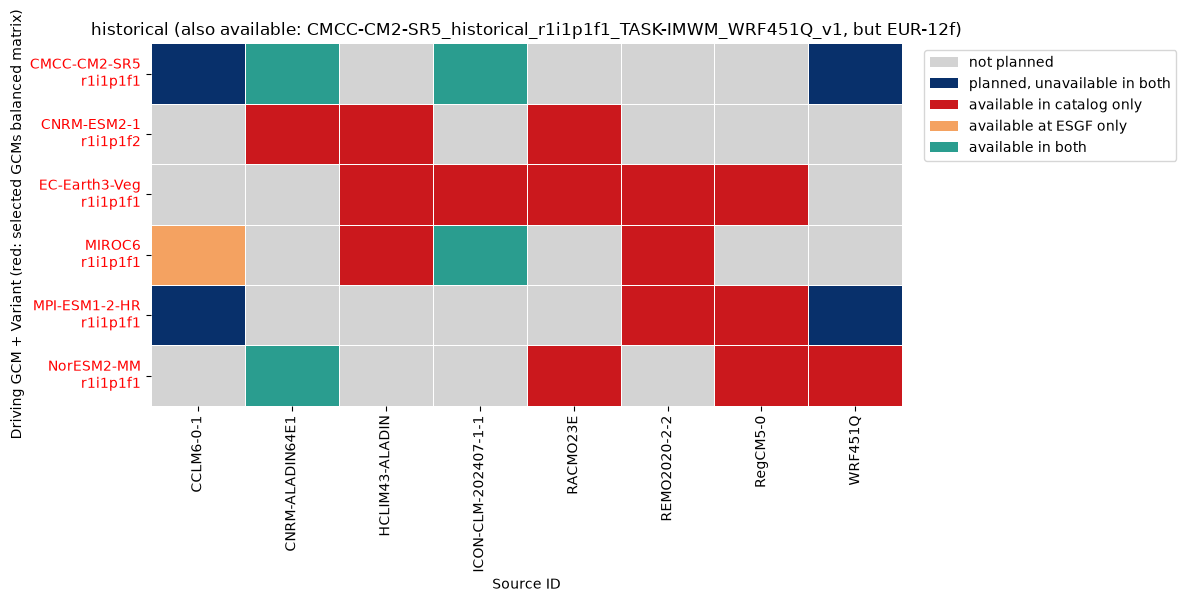

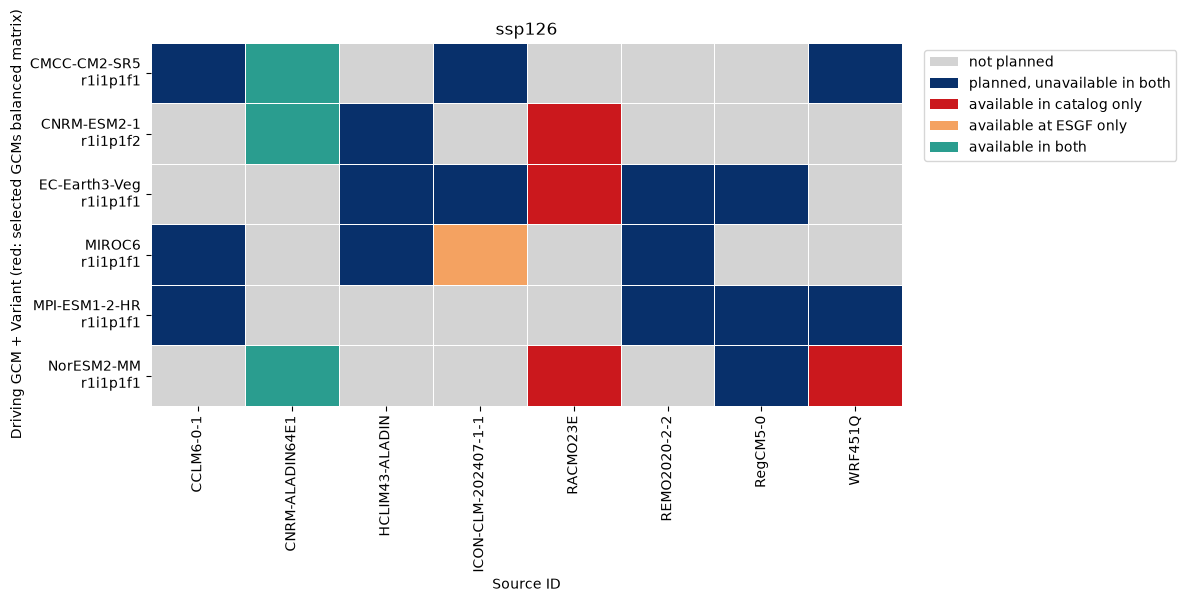

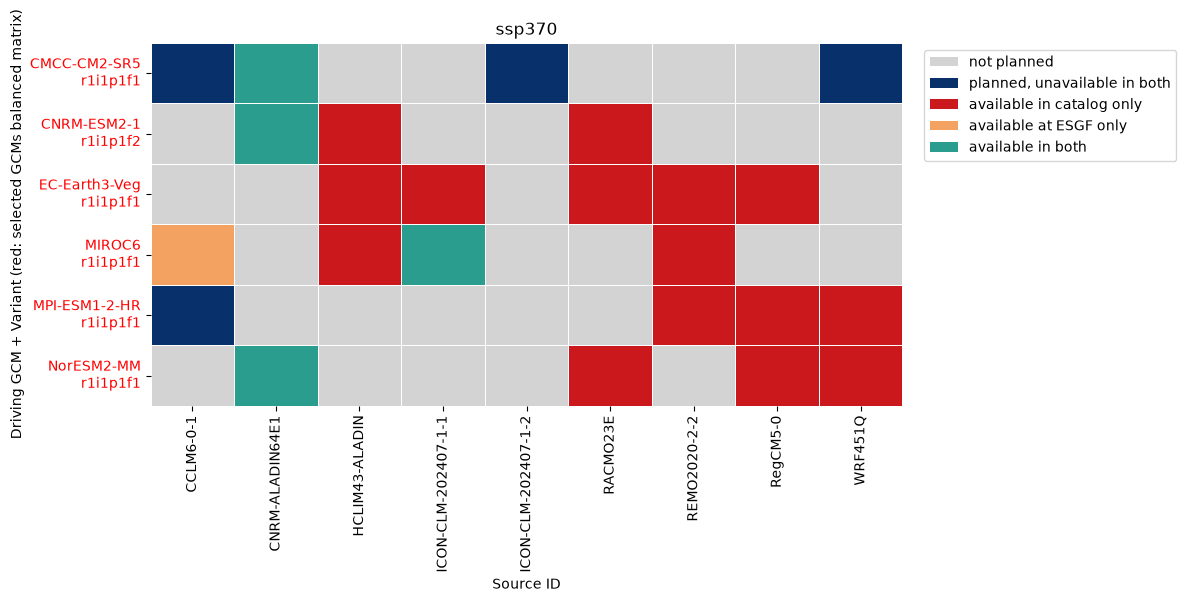

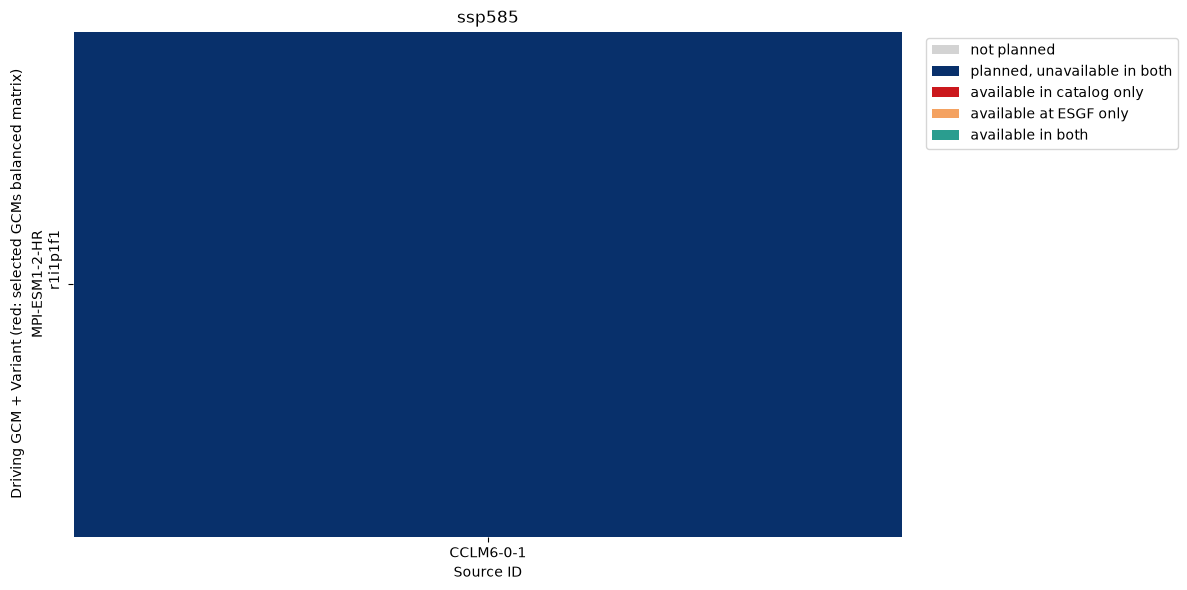

In [82]:
# --------------------------------------------
# Just decide on the matrix you like to plot
# --------------------------------------------

#df = pd.read_csv("CMIP6_downscaling_plans_checked.csv")
df = pd.read_csv("CMIP6_downscaling_plans_checked_esgf.csv")
#
# or balance matrix
#
df_eurbalanced = create_balanced_matrix(df)
# Adjust here the df name:
plot_cmip6_heatmaps(df_eurbalanced, plot_dir, "_balancedserver_esgf") 